# 0. Prepare HPF data (optional)

Builds the processed inputs in `data/` from the full datasets. **You only need to run this to regenerate those files.** To reproduce the analysis, download the processed files (see README) and start at notebook 1.

Steps:
1. Subset the Xenium spatial data to hippocampal formation (HPF) glutamatergic clusters.
2. Subset the snRNA-seq data to the same clusters and transfer each cluster's modal spatial section (`z_order`) to its cells.
3. Subset the HPF ATAC cells × peaks matrix to the peaks in the eRegulon triplets.
4. Plot the HPF groups in aligned 3D space.

**Inputs** (`data/raw/`, see `config.py`): Xenium `.h5ad`, snRNA-seq `.h5ad`, cluster annotation table, aligned spatial coordinates, full ATAC peak matrix; plus `data/eRegulon_direct.tsv`.

**Outputs:**
- `data/spatial_hpf_data_subset_spatially_variable_genes.h5ad` → notebook 1
- `data/rna_hpf_data_subset.h5ad` → notebook 2
- `data/hpf_atac_cells_by_eregulon_peaks.h5ad` → notebook 2
- `results/spatial_HPF_AP_Aligned_Scatter.png`

In [ ]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

from config import (SPATIAL_RAW_H5AD, RNA_RAW_H5AD, ANNO_TABLE_CSV, ALIGNMENT_CSV, ATAC_PEAKS_FULL_H5AD,
                    EREGULON_TSV, SPATIAL_HPF_H5AD, RNA_HPF_H5AD, ATAC_PEAKS_H5AD, RESULTS_DIR,
                    GROUP_PALETTE, set_plot_style)

set_plot_style()

In [ ]:
## parameters
# non-neuronal marker genes to remove from the Xenium gene panel
nn_marker_remove = ['AQP4', 'GFAP', 'MEGF10', 'BCAS1', 'VCAN', 'CLDN5', 'PECAM1',
                    'MFSD2A', 'RGS5', 'LRP2', 'CD3D']

z_column = 'z_order'
z_order_position = 17   # first section in which the HPF appears
damaged_section = 34    # section excluded because of tissue damage
spatial_cluster_col = 'Cluster_v4_name'
count_thres = 10        # min. cells in a cluster's modal section to keep the cluster
hpf_groups = ['CA3 Glut', 'CA1-ProS Glut', 'SUB-ProS Glut', 'DG Glut', 'CA2-CA3-IG Glut']

In [ ]:
## load data
spatial_data = sc.read_h5ad(SPATIAL_RAW_H5AD)
spatial_data = spatial_data[spatial_data.obs['qc_pass']]  # filter out low-quality cells
rna_data = sc.read_h5ad(RNA_RAW_H5AD, backed='r')
alignment = pd.read_csv(ALIGNMENT_CSV, index_col=0)

anno_table = pd.read_csv(ANNO_TABLE_CSV, index_col=0)
hpf_clusters = anno_table[anno_table['Subcortex_Group_v4'].isin(hpf_groups)].index.tolist()
anno_table = anno_table.drop(columns=['Figure_Panel', 'Panel_sections',
       'Panel_Purpose', 'Subcortex_Class_v4_BG', 'Subcortex_color_hex_cluster',
       'Subcortex_color_hex_cluster_display', 'Cluster_v4_size', 'Cluster_NT',
       'Cluster_Dominant_Region', 'inconclusive_mapping', 'Group_UID',
       'Group_Dominant_Region', 'Group_NT', 'Subcortex_Group_v4_color_hex',
       'BG_color_hex_group', 'BG_color_hex_subclass', 'BG_color_hex_class',
       'BG_color_hex_neighborhood', 'BG_Group', 'BG_Subclass', 'BG_Class',
       'BG_Neighborhood'], errors='ignore')

## 1. Filter spatial data for spatially variable gene analysis

In [4]:
spatial_data_subset = spatial_data[spatial_data.obs[spatial_cluster_col].isin(hpf_clusters)]

## update the spatial annotation to match the annotation table
spatial_data_subset.obs = spatial_data_subset.obs.drop(columns=spatial_data_subset.obs.columns[spatial_data_subset.obs.columns.isin(anno_table.columns)], errors='ignore')
spatial_data_subset.obs = spatial_data_subset.obs.merge(anno_table, left_on=spatial_cluster_col, right_index=True, how='left')

## keep sections from z_order_position onward (where the HPF appears) and drop the damaged section
spatial_data_subset.obs[z_column] = spatial_data_subset.obs[z_column].astype(int)
spatial_data_subset = spatial_data_subset[spatial_data_subset.obs[z_column] >= z_order_position]
spatial_data_subset = spatial_data_subset[spatial_data_subset.obs[z_column] != damaged_section]

## remove non-neuronal genes from the gene panel
spatial_data_subset = spatial_data_subset[:, ~spatial_data_subset.var_names.isin(nn_marker_remove)]
print(spatial_data_subset.shape)  # (198351, 289)

spatial_data_subset.write_h5ad(SPATIAL_HPF_H5AD, compression='gzip')

(198351, 289)


## 2. Filter clusters and transfer spatial z to the snRNA-seq data

In [ ]:
## modal z section (and its cell count) for each spatial cluster
spatial_cluster_z_mode = spatial_data_subset.obs[[spatial_cluster_col, z_column]].value_counts().reset_index()
spatial_cluster_z_mode = spatial_cluster_z_mode.groupby(spatial_cluster_col, observed=False).apply(lambda x: x.loc[x['count'].idxmax()])

## keep clusters whose modal section has >= count_thres cells
spatial_clusters_to_keep = spatial_cluster_z_mode.loc[
    spatial_cluster_z_mode['count'] >= count_thres, spatial_cluster_col
].tolist()

spatial_data_subset = spatial_data_subset[
    spatial_data_subset.obs[spatial_cluster_col].isin(spatial_clusters_to_keep)
].copy()
spatial_cluster_z_mode = spatial_cluster_z_mode[
    spatial_cluster_z_mode[spatial_cluster_col].isin(spatial_clusters_to_keep)
]

## map each retained cluster to its modal z section and transfer it to the snRNA-seq cells
z_order_dict = dict(zip(spatial_cluster_z_mode[spatial_cluster_col], spatial_cluster_z_mode[z_column]))

rna_data_subset = rna_data[rna_data.obs['Cluster_v4'].isin(spatial_data_subset.obs[spatial_cluster_col].unique())].to_memory()
rna_data_subset.obs[z_column] = rna_data_subset.obs['Cluster_v4'].map(z_order_dict)

merge_anno_col = ['Subcortex_Class_v4', 'Subcortex_Group_v4']
rna_data_subset.obs = (rna_data_subset.obs.drop(columns=merge_anno_col, errors='ignore')
                       .merge(anno_table[merge_anno_col], left_on='Cluster_v4', right_index=True, how='left'))

In [ ]:
## save the processed snRNA-seq data
rna_data_subset.write_h5ad(RNA_HPF_H5AD, compression='gzip')

## 3. Subset the HPF ATAC matrix to eRegulon peaks

In [ ]:
## keep only peaks that appear in the eRegulon triplets (reduces file size ~4x)
ereg_trip = pd.read_csv(EREGULON_TSV, sep='\t', index_col=0)
atac = sc.read_h5ad(ATAC_PEAKS_FULL_H5AD)
atac_sub = atac[:, atac.var_names.isin(ereg_trip.index.unique())].copy()
print(f'{atac.shape} -> {atac_sub.shape}')

atac_sub.write_h5ad(ATAC_PEAKS_H5AD, compression='gzip')
del atac, atac_sub

## 4. Visualize HPF groups in aligned 3D space

In [ ]:
## add aligned coordinates
alignment = alignment[alignment.index.isin(spatial_data_subset.obs_names)]
alignment_df = pd.DataFrame(index=spatial_data_subset.obs_names, columns=['x', 'y'], data=np.nan)
alignment_df.loc[alignment.index] = alignment[['x', 'y']].values
spatial_data_subset.obsm['spatial_aligned'] = alignment_df.values

## for visualization only: remove outliers in aligned coordinates (1.5 x IQR rule)
def remove_outliers(adata, coords):
    df = pd.DataFrame(coords, index=adata.obs_names, columns=['x', 'y'])
    Q1 = df.quantile(0.25)
    Q3 = df.quantile(0.75)
    IQR = Q3 - Q1
    return ~((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).any(axis=1)

keep = remove_outliers(spatial_data_subset, spatial_data_subset.obsm['spatial_aligned'])
spatial_data_subset = spatial_data_subset[keep]

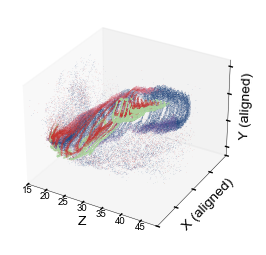

In [8]:
## 3D scatter of HPF groups along the AP axis
plot_df = pd.DataFrame({
    'x': -spatial_data_subset.obsm['spatial_aligned'][:, 0],
    'y': -spatial_data_subset.obsm['spatial_aligned'][:, 1],
    'z': spatial_data_subset.obs[z_column],
    'Group': spatial_data_subset.obs['Subcortex_Group_v4']
})

y_thres = -10000
plot_df = plot_df[plot_df['y'] < y_thres]

fig = plt.figure(figsize=(4, 3))
ax = fig.add_subplot(111, projection='3d')
group_to_color = {group: GROUP_PALETTE[group] for group in hpf_groups}
colors = plot_df['Group'].map(group_to_color)

ax.scatter(plot_df['z'], plot_df['x'], plot_df['y'], c=colors, s=0.1, marker='o', edgecolors='none', rasterized=True)
ax.set_yticklabels([])
ax.set_zticklabels([])
ax.tick_params(axis='x', labelsize=7, pad=-7)
for group, color in group_to_color.items():
    ax.scatter([], [], [], color=color, label=group, s=10)

ax.set_ylim(-8000, 0)
ax.set_xlabel('Z', labelpad=-12)
ax.set_ylabel('X (aligned)', labelpad=-11)
ax.set_zlabel('Y (aligned)', labelpad=-13)
ax.grid(False)
plt.savefig(RESULTS_DIR / 'spatial_HPF_AP_Aligned_Scatter.png',
            format='png', bbox_inches='tight', transparent=True, dpi=500)